In [75]:
from pathlib import Path
import hashlib, io, json
from datetime import datetime, timezone
import requests
import pandas as pd
import yfinance as yf

PROJECT_ROOT = Path.cwd().resolve()
while not ((PROJECT_ROOT / "notebooks").is_dir() and (PROJECT_ROOT / "data").is_dir()):
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Start the notebook from inside the portfolio repository.")
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / "data" / "collection"
RAW_DIR.mkdir(parents=True, exist_ok=True)
COLLECTION_START = "2010-01-01"
COLLECTION_END_EXCLUSIVE = "2026-07-01"     # until 2026-06-30, data for evaluation
PRICE_FILENAME = "Full Historical_Adj_Close_2010_2026.csv"
BENCHMARK_FILENAME = "Benchmark_SPY_Adj_Close_2010_2026.csv"
RISK_FREE_FILENAME = "Risk_Free_DGS3MO_2010_2026.csv"
SECTOR_FILENAME = "sector_map.csv"
COLLECT_RISK_FREE = True
ONLY_MEMBERS_SINCE = None               # chỉ giữ mã đã nằm trong S&P 500 từ trước 2010

url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=30).text   # Wikipedia chặn request không có User-Agent
sp500 = pd.read_html(io.StringIO(html))[0]
sp500["Ticker"] = sp500["Symbol"].str.replace(".", "-", regex=False)                # BRK.B -> BRK-B (kiểu Yahoo)
sp500["Date added"] = pd.to_datetime(sp500["Date added"], errors="coerce")
if ONLY_MEMBERS_SINCE:
    sp500 = sp500[sp500["Date added"] <= ONLY_MEMBERS_SINCE]
sp500.to_csv(RAW_DIR / "sp500_constituents_snapshot.csv", index=False)              # ảnh chụp danh sách, để tái lập
tickers = sorted(sp500["Ticker"])
print(len(tickers), "candidate tickers")

def dl_adj_close(symbols, chunk=100):
    parts = []
    for i in range(0, len(symbols), chunk):
        part = symbols[i:i + chunk]
        d = yf.download(part, start=COLLECTION_START, end=COLLECTION_END_EXCLUSIVE, interval="1d",
                        auto_adjust=False, keepna=True, progress=False, threads=True)
        if d is None or d.empty or "Adj Close" not in d.columns.get_level_values(0):
            raise ValueError(f"No usable download for chunk starting at {part[0]}")
        x = d["Adj Close"]
        parts.append(x.to_frame(part[0]) if isinstance(x, pd.Series) else x)
    return pd.concat(parts, axis=1)

adjusted = dl_adj_close(tickers)
benchmark_prices = dl_adj_close(["SPY"])

first = pd.to_datetime(adjusted.apply(pd.Series.first_valid_index))
last = pd.to_datetime(adjusted.apply(pd.Series.last_valid_index))
full = (first <= adjusted.index[0]) & (last >= pd.Timestamp("2026-06-26"))
adj_close = adjusted.loc[:, full[full].index].ffill(limit=5).dropna(axis=1)
dropped = sorted(set(tickers) - set(adj_close.columns))
print(f"{len(tickers)} candidates -> {adj_close.shape[1]} stocks with full history; dropped {len(dropped)}")
pd.Series(dropped, name="dropped_ticker").to_csv(RAW_DIR / "dropped_tickers.csv", index=False)

adj_close.to_csv(RAW_DIR / PRICE_FILENAME, index_label="Date")
benchmark_prices.to_csv(RAW_DIR / BENCHMARK_FILENAME, index_label="Date")
(sp500.set_index("Ticker").loc[adj_close.columns, "GICS Sector"].rename("Sector")
      .to_csv(RAW_DIR / SECTOR_FILENAME, index_label="Ticker"))
print("Stock and benchmark files saved to", RAW_DIR)
print("Actual stock coverage:", adj_close.index.min(), "to", adj_close.index.max())

503 candidate tickers


$VYLR: Data doesn't exist for startDate = 1262322000, endDate = 1782878400

1 Failed download:
['VYLR']: Data doesn't exist for startDate = 1262322000, endDate = 1782878400


503 candidates -> 417 stocks with full history; dropped 86
Stock and benchmark files saved to /Users/hangph05/Documents/portfolio/data/collection
Actual stock coverage: 2010-01-04 00:00:00 to 2026-06-30 00:00:00


In [77]:
if COLLECT_RISK_FREE:
    final_date = (pd.Timestamp(COLLECTION_END_EXCLUSIVE) - pd.Timedelta(days=1)).date().isoformat()
    url = ("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS3MO"
           f"&cosd={COLLECTION_START}&coed={final_date}")
    risk_free_yield = pd.read_csv(url, na_values=["."])
    risk_free_yield = risk_free_yield.rename(columns={risk_free_yield.columns[0]: "Date"})
    risk_free_yield["Date"] = pd.to_datetime(risk_free_yield["Date"])
    risk_free_yield["DGS3MO"] = pd.to_numeric(risk_free_yield["DGS3MO"], errors="raise")
    if risk_free_yield["DGS3MO"].notna().sum() == 0:
        raise ValueError("FRED returned no yield observations.")
    risk_free_yield.to_csv(RAW_DIR / RISK_FREE_FILENAME, index=False)

files = [PRICE_FILENAME, BENCHMARK_FILENAME, SECTOR_FILENAME]
if COLLECT_RISK_FREE:
    files.append(RISK_FREE_FILENAME)
collection_metadata = {
    "start_inclusive": COLLECTION_START,
    "end_exclusive": COLLECTION_END_EXCLUSIVE,
    "downloaded_at_utc": datetime.now(timezone.utc).isoformat(),
    "universe_source": "Wikipedia S&P 500 current constituents snapshot; survivors only (survivorship bias)",
    "only_members_since": ONLY_MEMBERS_SINCE,
    "n_candidates": len(tickers), "n_kept": int(adj_close.shape[1]),
    "tickers": list(adj_close.columns), "benchmark": "SPY", "auto_adjust": False,
    "selected_field": "Adj Close", "yfinance_version": yf.__version__,
    "risk_free_series": "DGS3MO" if COLLECT_RISK_FREE else None,
    "risk_free_units": "percent per annum, investment-basis yield; not realized returns",
    "sha256": {name: hashlib.sha256((RAW_DIR / name).read_bytes()).hexdigest() for name in files},
}
(RAW_DIR / "collection_metadata.json").write_text(json.dumps(collection_metadata, indent=2) + "\n")
print(adj_close.isna().sum().sort_values(ascending=False).head())
print("Duplicate price dates:", int(adj_close.index.duplicated().sum()))

Ticker
A       0
J       0
OKE     0
ODFL    0
O       0
dtype: int64
Duplicate price dates: 0


In [79]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
PROJECT_ROOT = PROJECT_ROOT.parent if PROJECT_ROOT.name == "notebooks" else PROJECT_ROOT
DATA_DIR = PROJECT_ROOT / "data/collection"
OUTPUT_DIR = PROJECT_ROOT / "data/preparation"
TRADING_DAYS = 252
SECTOR_MAP = pd.read_csv(DATA_DIR / "sector_map.csv", index_col="Ticker")["Sector"].to_dict()

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_rows", 25)

In [81]:
prices = pd.read_csv(DATA_DIR / "Full Historical_Adj_Close_2010_2026.csv", index_col="Date", parse_dates=True).sort_index()
returns_all = prices.pct_change(fill_method=None).iloc[1:]
log_returns_all = np.log(prices).diff().iloc[1:]
returns = returns_all.loc[returns_all.index < "2025-01-01"]
evaluation_returns = returns_all.loc["2025-01-01":"2026-06-30"]
print("Training dates:", len(returns), "| evaluation dates:", len(evaluation_returns))

Training dates: 3773 | evaluation dates: 373


In [83]:
mu = returns.mean()
covariance = returns.cov(ddof=1)
correlation = returns.corr()

In [85]:
#pick random 2 asset
a, b = np.random.default_rng(1).choice(returns.columns, size=2, replace = False)
mupair = mu[[a,b]]
covpair = covariance.loc[[a,b],[a,b]]
mu_a, mu_b = mupair[a], mupair[b]
covaa, covbb, covab = covpair.loc[a,a], covpair.loc[b,b], covpair.loc[a,b]
print(f"pair : {a}, {b}")
print(f"mu_a = {mu_a:.6f} mu_b={mu_b: .6f}")
print(f"var_a={covaa:.6f}  var_b={covbb:.6f}  cov_ab={covab:.6f}")

pair : IDXX, JKHY
mu_a = 0.000890 mu_b= 0.000675
var_a=0.000333  var_b=0.000189  cov_ab=0.000113


In [87]:
#GMV of 2 asset 
print("FORMULA FOR CASE OF 2 ASSETS")
wb = (covaa - covab)/(covaa + covbb - 2*covab)
wa = 1 - wb
mu_portfolio_pair = wa*mu_a + wb*mu_b
var_portfolio_pair = wa**2*covaa + wb**2*covbb + 2*wa*wb*covab
vol_portfolio_pair = np.sqrt(var_portfolio_pair)
print(f"weight of HD : {wa:.4f}")
print(f"weight of IBM : {wb:.4f}")
print(f"Portfolio expected return : {mu_portfolio_pair: .4f}")
print(f"Porfolio volatility : {vol_portfolio_pair:.4f}")

#GMV of general case
print("FORMULA FOR GENERAL CASE")
inv, ones = np.linalg.inv(covpair.to_numpy()), np.ones(2)
wg = (inv@ones)/(ones@inv@ones)
mu_portfolio2 = wg@mupair.to_numpy()
var_portfolio2 = wg@covpair.to_numpy()@wg
vol_portfolio2 = np.sqrt(var_portfolio2)
print(f"weight of HD : {wg[0]:.4f}")
print(f"weight of IBM : {wg[1]:.4f}")
print(f"Portfolio expected return : {mu_portfolio2: .4f}")
print(f"Porfolio volatility : {vol_portfolio2:.4f}")

FORMULA FOR CASE OF 2 ASSETS
weight of HD : 0.2574
weight of IBM : 0.7426
Portfolio expected return :  0.0007
Porfolio volatility : 0.0130
FORMULA FOR GENERAL CASE
weight of HD : 0.2574
weight of IBM : 0.7426
Portfolio expected return :  0.0007
Porfolio volatility : 0.0130


In [89]:
# ===== CELL A (mới): cấu hình, chia danh mục 25 mã (không swap) =====
from scipy.optimize import minimize

SEED = 42
N_PORT = 25                    # số mã mỗi danh mục
MIN_PER_SECTOR = 1             # mỗi sector phải có mặt trong mọi danh mục
MAX_SECTOR_SHARE = 0.20        # một sector chiếm tối đa 20% danh mục (= 5 mã khi N_PORT = 25)
LOOKBACK_YEARS = 15             
TD = TRADING_DAYS

est = returns.loc[f"{2025 - LOOKBACK_YEARS}-01-01":"2024-12-31"]      # chỉ dữ liệu training
oos = evaluation_returns                                               # 2025-01 .. 2026-06, không train

universe = list(returns.columns)
missing = [t for t in universe if t not in SECTOR_MAP]
assert not missing, f"SECTOR_MAP is missing: {missing}"
sectors = sorted(set(SECTOR_MAP[t] for t in universe))

def make_portfolios(universe, seed):
    rng = np.random.default_rng(seed)
    K = len(universe) // N_PORT                                           # số danh mục
    keep = [str(t) for t in rng.permutation(universe)[:N_PORT * K]]       # bỏ ngẫu nhiên phần dư
    order = sorted(keep, key=lambda t: (SECTOR_MAP[t], rng.random()))     # gom theo sector, xáo trộn trong sector
    return {f"P{k}": order[k::K] for k in range(K)}                       # chia vòng tròn: sector nào cũng rải đều

def sector_counts(portfolios):
    return (pd.DataFrame({p: pd.Series([SECTOR_MAP[t] for t in ts]).value_counts() for p, ts in portfolios.items()})
              .reindex(sectors).fillna(0).astype(int))

def n_violations(portfolios):
    c = sector_counts(portfolios)
    return int((c < MIN_PER_SECTOR).sum().sum() + (c > int(MAX_SECTOR_SHARE * N_PORT)).sum().sum())

best = None
for s in range(SEED, SEED + 200):                                       
    p = make_portfolios(universe, s)
    v = n_violations(p)
    if best is None or v < best[0]:
        best = (v, s, p)
    if v == 0:
        break
violations, used_seed, portfolios = best
print(f"{len(portfolios)} portfolios x {N_PORT} stocks | seed {used_seed} | dropped {len(universe) - N_PORT * len(portfolios)} stocks | "
      f"violations of diversification rules: {violations}")
display(sector_counts(portfolios))

16 portfolios x 25 stocks | seed 46 | dropped 17 stocks | violations of diversification rules: 3


,P0,P1,P2,P3,P4,P5,P6,P7,P8,P9,P10,P11,P12,P13,P14,P15
Communication Services,1,1,1,1,1,1,1,1,1,1,1,1,1,1,0,0
Consumer Discretionary,3,3,3,2,2,2,2,2,2,2,2,2,2,2,3,3
Consumer Staples,2,1,1,2,2,2,2,2,2,2,2,2,2,2,2,2
Energy,0,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
Financials,4,4,4,4,4,4,4,4,4,4,4,4,3,3,3,3
Health Care,3,3,3,3,3,3,3,3,3,3,3,3,4,4,3,3
Industrials,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4
Information Technology,4,4,4,4,4,3,3,3,3,3,3,3,3,3,4,4
Materials,1,1,1,1,1,2,2,2,2,2,1,1,1,1,1,1
Real Estate,2,2,2,2,2,1,1,1,1,1,2,2,2,2,2,2


In [91]:
def w_equal(mu,S):
    return np.full(len(mu), 1/len(mu))

def w_gmv_unrestricted (mu,S):
    x = np.linalg.solve(S, np.ones(len(S))) #solve Sx = 1 ~ x = inv(S)@1
    return x/x.sum() #w=inv(S)1 / (1'inv(S)1)
    
#thêm condition upper = 0.1
def w_optimize (mu, S, target = None, lower = 0.0, upper = None):
    n = len(mu)
    cons = [{"type": "eq",     #eq = quality constraint: fun(w) = 0
             "fun": lambda w: w.sum() - 1, #total weights must = 1
             "jac": lambda w: np.ones(n)}] #Jacobien (gradient) of the constraint
    if target is not None:
        cons.append({
            "type": "eq",
            "fun": lambda w: mu@w - target, #expected return of portfolio = target
            "jac": lambda w: mu})
    res = minimize(lambda w: w@S@w, #min portfolio variance
                   np.full(n, 1/n), #initial equal weights
                   jac = lambda w: 2*S@w, #gradient of objective function (constaint)
                   bounds =[(lower,upper)]*n, #weight bounds for each stock
                   constraints = cons, method = "SLSQP",
                   options =  {"ftol": 1e-12, "maxiter": 1000}) #tolerance and max iterations
    if not res.success:
        raise RuntimeError(res.message) #raise error if optimization fails
    w = res.x.copy()
    w[np.abs(w) < 1e-8]=0.0 #set tiny weights to zero
    return w/w.sum() #normalize weights to sum to 1

def w_target_unrestricted (mu,S,target):
    x1=np.linalg.solve(S, np.ones(len(mu))) #inv(S)@1
    xm = np.linalg.solve(S,mu) #inv(S)@mu
    A, B, C = mu@xm, xm.sum(), x1.sum()
    D = A*C - B**2
    return ((C*target - B)*xm + (A - B*target)*x1)/D 

MODELS = {
    "1/N": w_equal,
    "GMV unrestricted": w_gmv_unrestricted,
    "GMV long-only": w_optimize,
    "Target return (unrestricted)": lambda mu, S: w_target_unrestricted (mu, S, float(mu.mean())),
    "Target return (long-only)": lambda mu, S: w_optimize(mu, S, target = float(mu.mean()))}

ret_in


model,1/N,GMV long-only,GMV unrestricted,Target return (long-only),Target return (unrestricted)
portfolio,,,,,
P0,19.64,16.57,15.67,19.64,19.64
P1,14.85,13.21,14.12,14.85,14.85
P10,18.60,15.71,15.09,18.60,18.60
P11,15.73,11.00,11.14,15.73,15.73
P12,18.34,13.75,13.55,18.34,18.34
P13,17.58,13.41,12.89,17.58,17.58
P14,18.54,15.08,13.85,18.54,18.54
P15,18.69,15.03,14.53,18.69,18.69
P2,16.01,15.93,15.55,16.01,16.01


vol_in


model,1/N,GMV long-only,GMV unrestricted,Target return (long-only),Target return (unrestricted)
portfolio,,,,,
P0,17.85,14.08,13.70,14.63,14.21
P1,18.33,15.24,14.62,15.35,14.64
P10,18.14,14.59,14.26,14.94,14.58
P11,17.57,13.38,12.79,14.95,13.56
P12,17.25,14.24,13.93,14.80,14.44
P13,18.19,14.09,13.82,14.71,14.35
P14,19.24,14.45,14.03,14.81,14.50
P15,18.14,13.62,13.42,14.22,13.86
P2,18.38,15.04,14.58,15.04,14.58


ret_oos


model,1/N,GMV long-only,GMV unrestricted,Target return (long-only),Target return (unrestricted)
portfolio,,,,,
P0,13.45,14.71,20.34,13.72,16.16
P1,15.77,6.55,6.70,1.30,5.18
P10,22.22,4.03,-6.64,1.30,-4.07
P11,24.67,23.08,20.86,22.59,18.79
P12,7.91,11.49,8.38,12.46,8.10
P13,18.32,16.21,18.32,15.39,14.89
P14,24.72,14.80,16.80,14.64,18.53
P15,19.36,4.17,4.05,7.51,8.19
P2,25.88,2.34,-0.38,2.15,-0.75


vol_oos


model,1/N,GMV long-only,GMV unrestricted,Target return (long-only),Target return (unrestricted)
portfolio,,,,,
P0,17.15,14.82,15.77,14.68,15.69
P1,16.24,14.41,14.87,14.47,14.82
P10,14.87,14.11,15.07,13.84,14.06
P11,16.07,14.37,14.32,14.30,14.42
P12,14.32,13.33,14.37,12.40,13.36
P13,17.56,14.54,14.84,15.34,15.15
P14,18.80,15.21,15.30,16.09,16.49
P15,17.60,15.00,15.38,13.94,14.23
P2,16.54,14.76,16.14,14.79,16.10


,n_eff,max_w,min_w,n_held
model,,,,
1/N,25.000,0.040,0.040,25.000
GMV long-only,6.661,0.271,0.000,13.062
GMV unrestricted,5.454,0.260,-0.090,25.000
Target return (long-only),7.726,0.216,0.000,13.125
Target return (unrestricted),5.539,0.231,-0.104,25.000


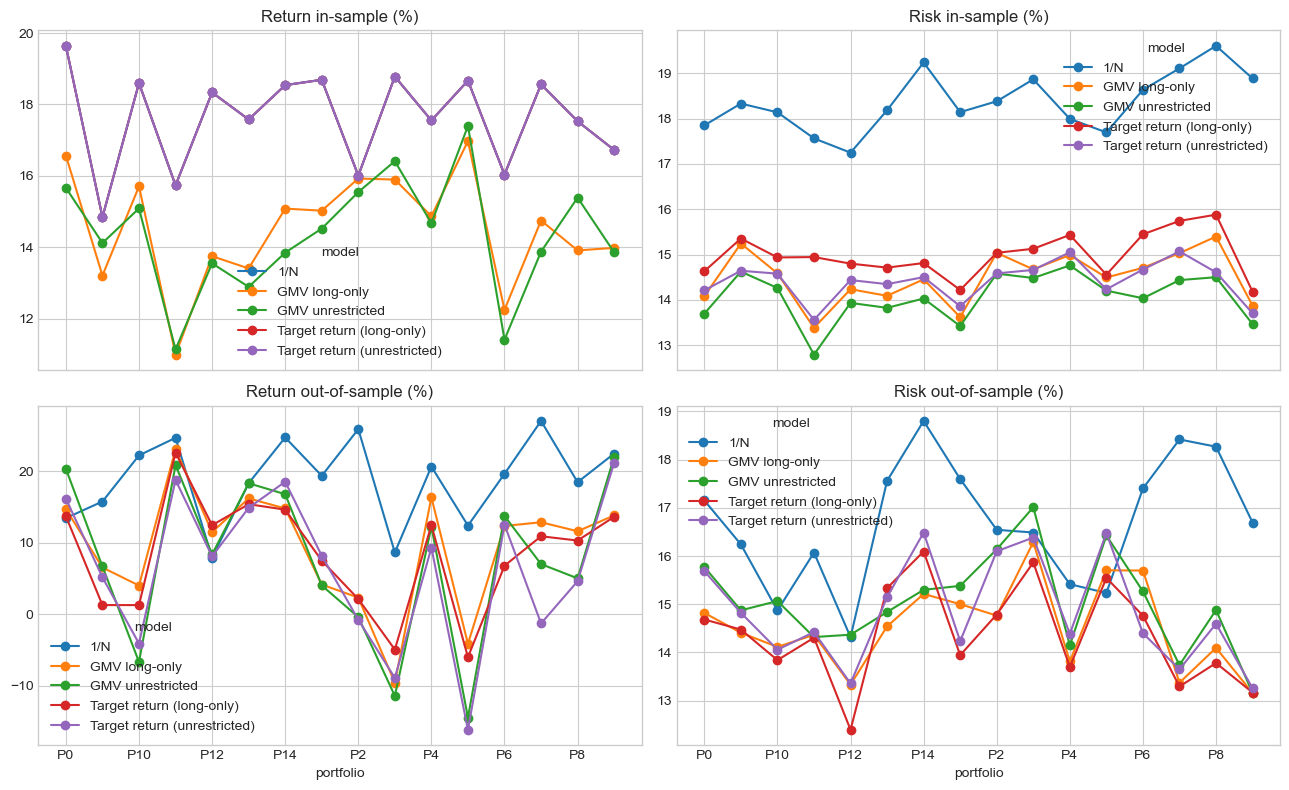

In [93]:
rows, weights = [], {}
for pid, tickers in portfolios.items():
    mu = est[tickers].mean().to_numpy()*TRADING_DAYS #mean annualized (in sample)
    S = est[tickers].cov().to_numpy()*TRADING_DAYS #covariance annualized
    oos_r = oos[tickers].to_numpy() #outofsample
    for name, model in MODELS.items():
        w = model(mu, S)
        weights[(pid,name)] = pd.Series(w, index = tickers)
        r_oos = oos_r @ w #portfolio daily return (out of sample)
        rows.append({"portfolio": pid, "model": name,
                     "ret_in": w @ mu, "vol_in": np.sqrt(w@S@w),
                     "ret_oos": r_oos.mean()*TRADING_DAYS,
                     "vol_oos": r_oos.std(ddof=1)*np.sqrt(TRADING_DAYS),
                     "n_eff": 1/(w**2).sum(), "max_w": w.max(), "min_w": w.min(),
                     "n_held": int((np.abs(w)>1e-6).sum())})
results = pd.DataFrame(rows)

for col in ["ret_in", "vol_in", "ret_oos", "vol_oos"]:
    print(col)
    display((
        results.pivot(index = "portfolio", columns = "model", values = col)*100).round(2))
display(results.groupby("model")[["n_eff", "max_w", "min_w", "n_held"]].mean().round(3))

fig, axes = plt.subplots(2,2, figsize = (13,8), sharex = True)
for ax, col, title in zip(axes.ravel(),
                          ["ret_in", "vol_in", "ret_oos", "vol_oos"],
                          ["Return in-sample (%)", "Risk in-sample (%)",
                           "Return out-of-sample (%)", "Risk out-of-sample (%)"]):
    (results.pivot(index = "portfolio", columns = "model", values = col)*100).plot(ax=ax, marker = "o", title=title)
plt.tight_layout()
plt.show()

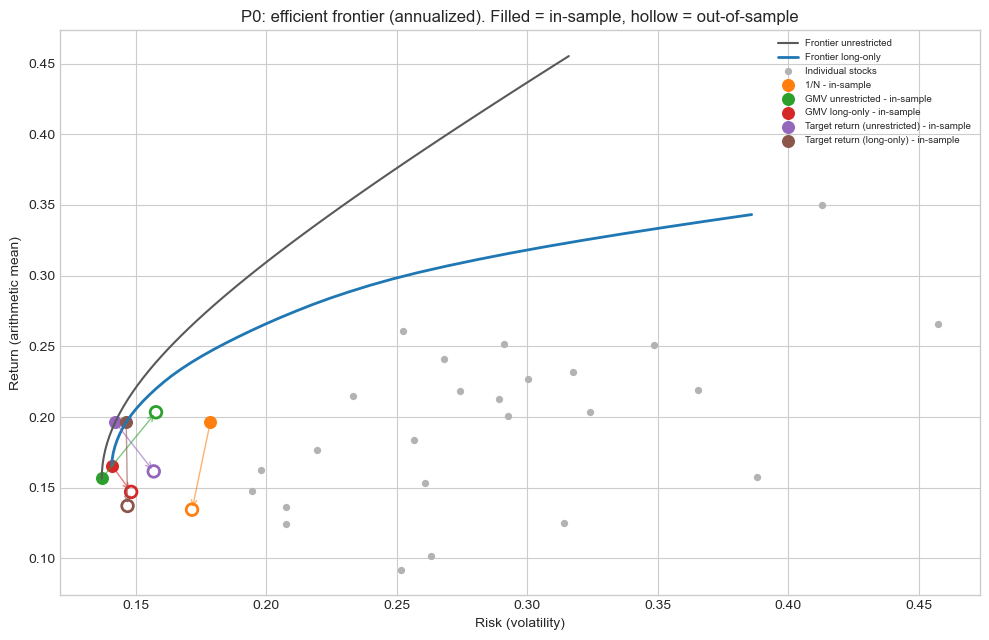

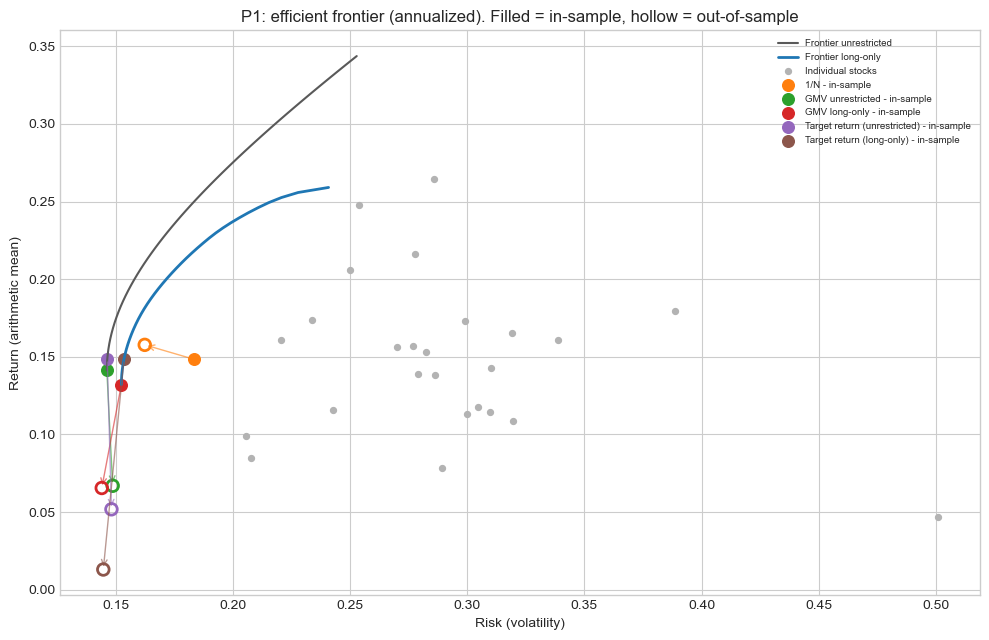

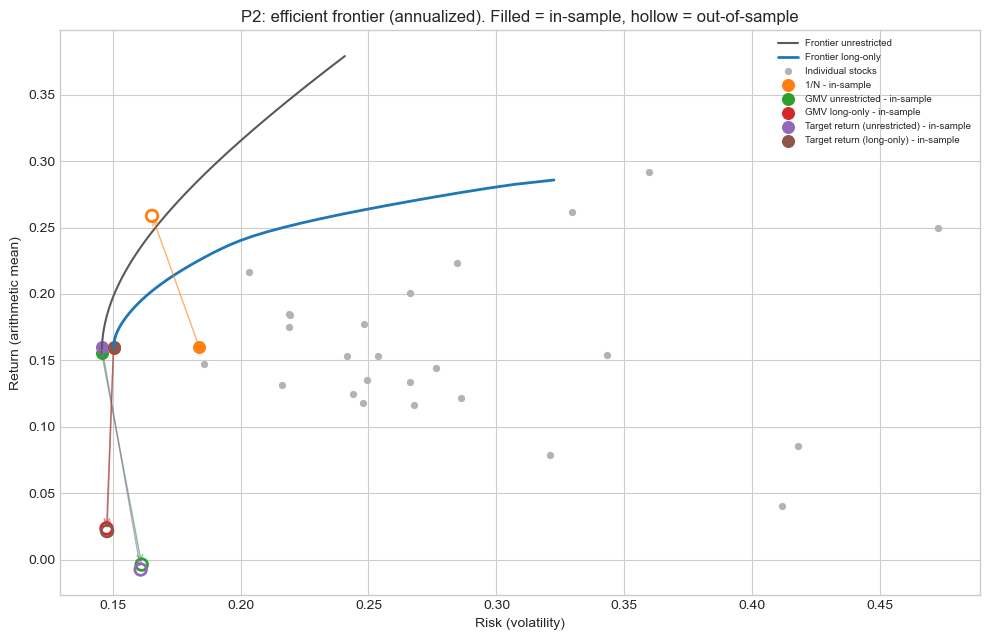

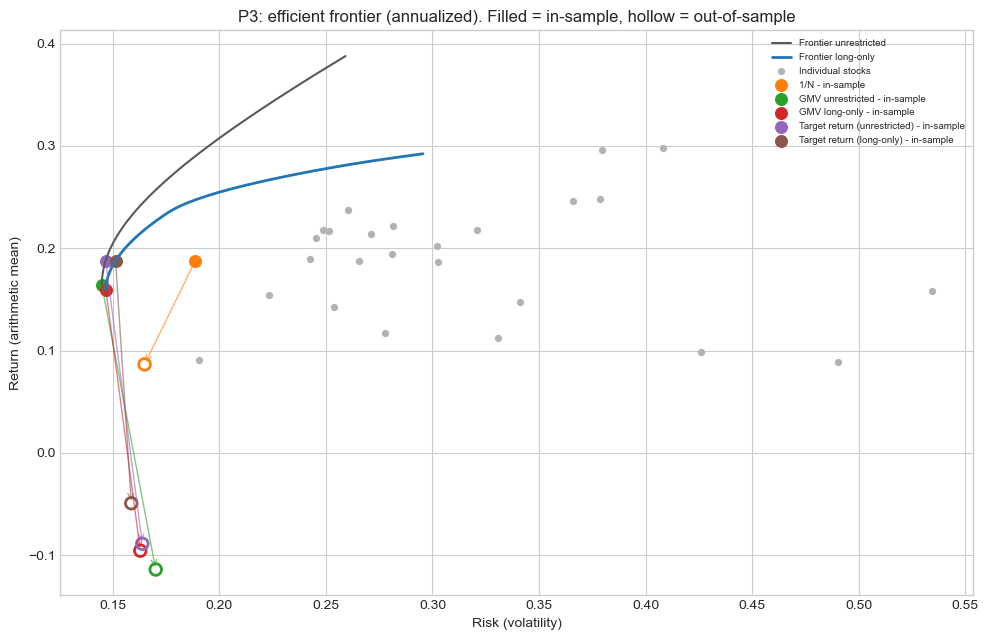

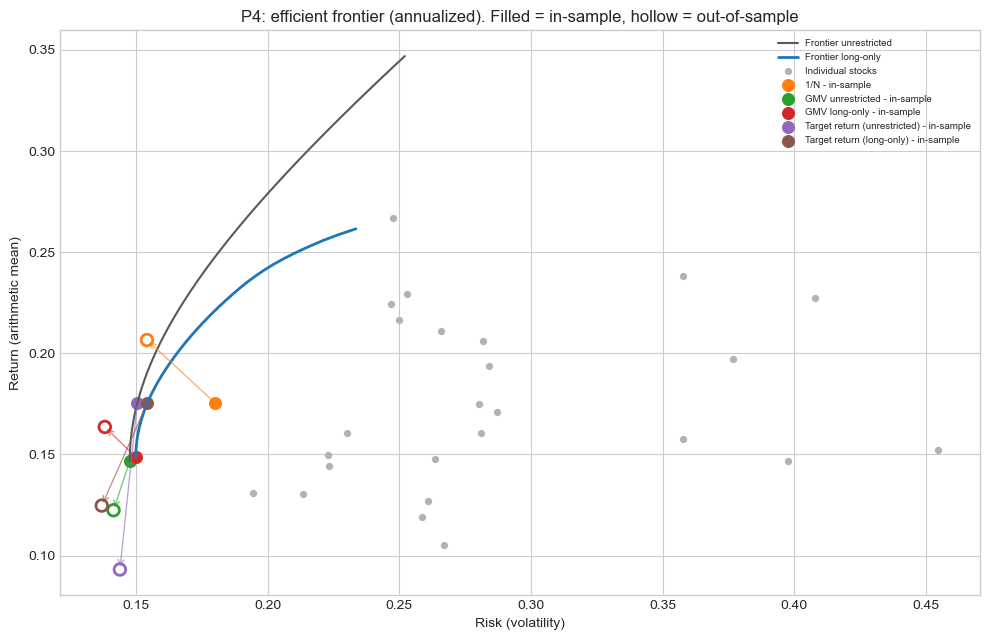

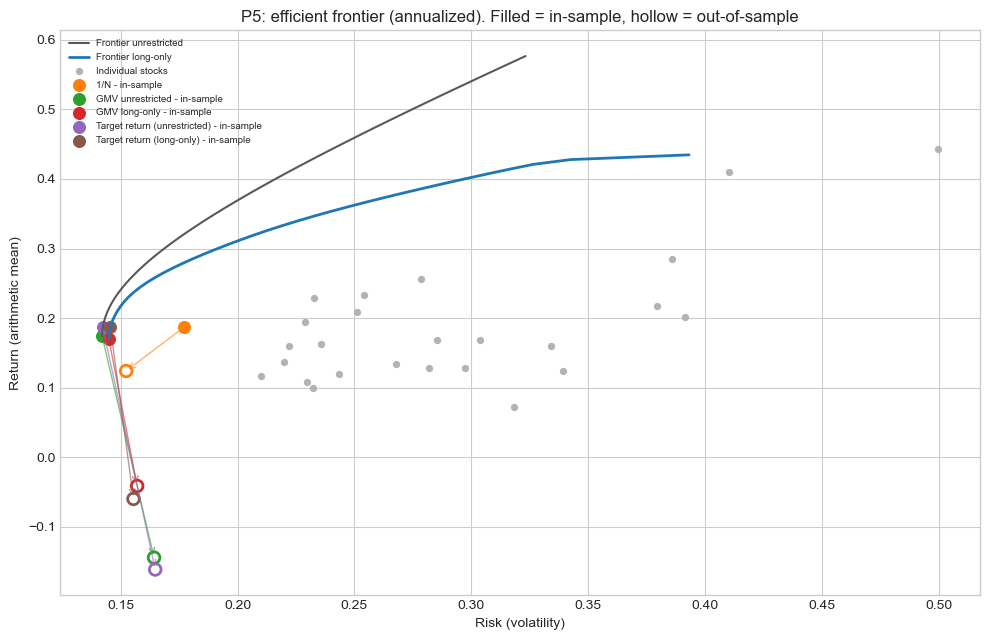

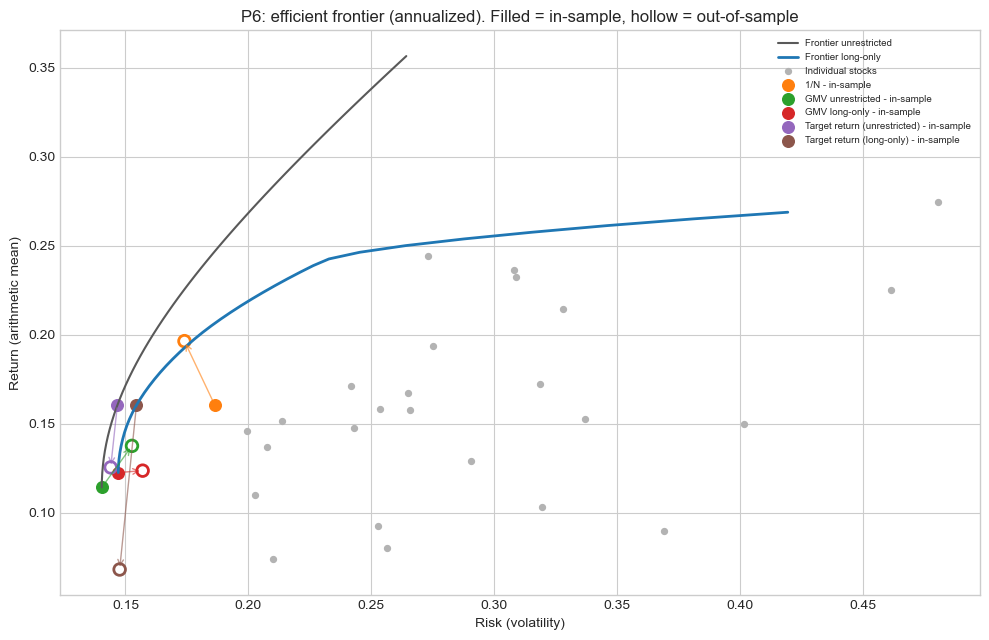

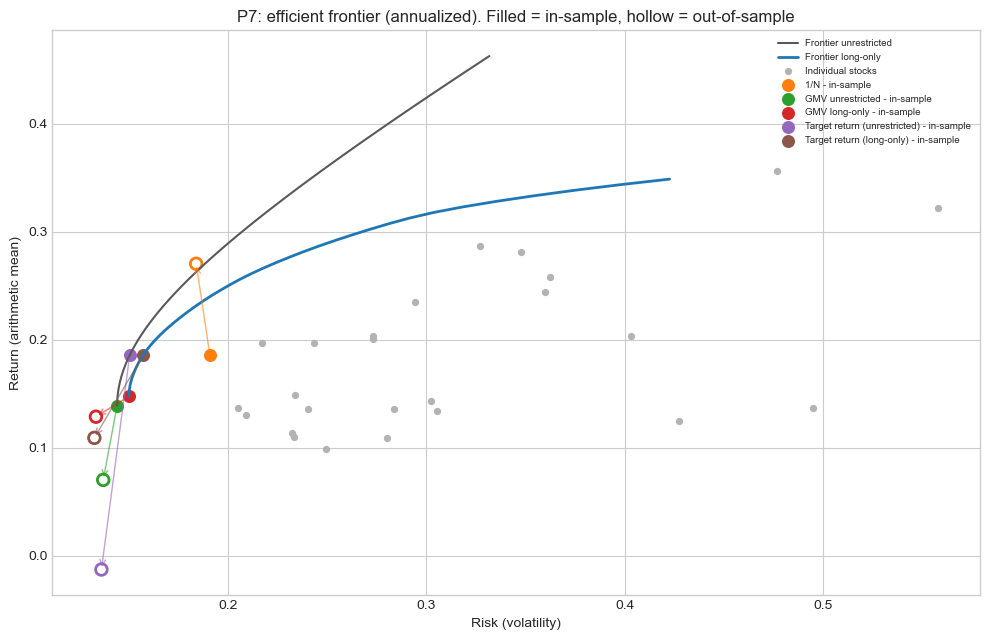

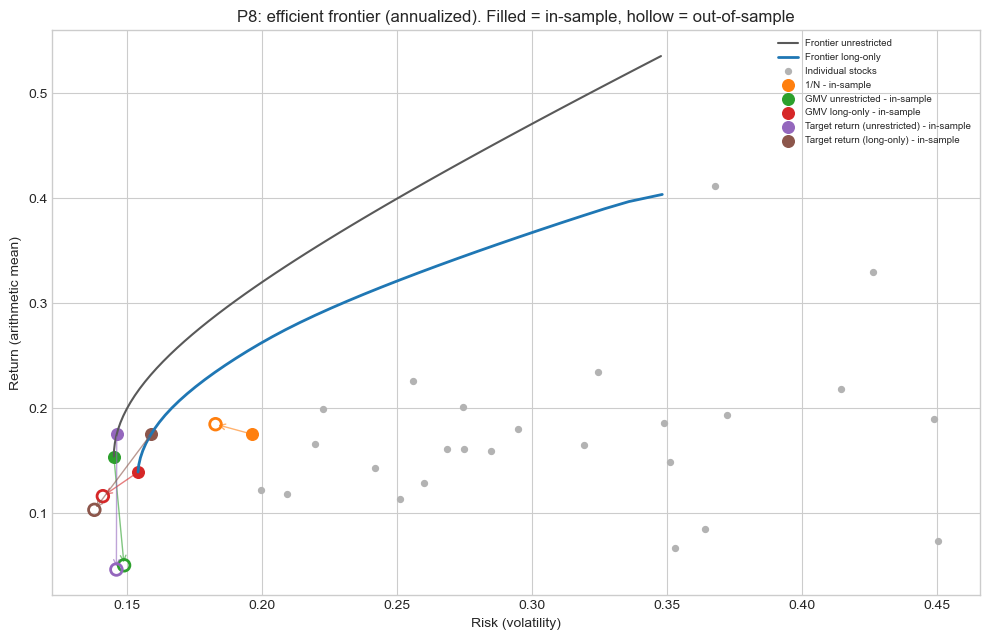

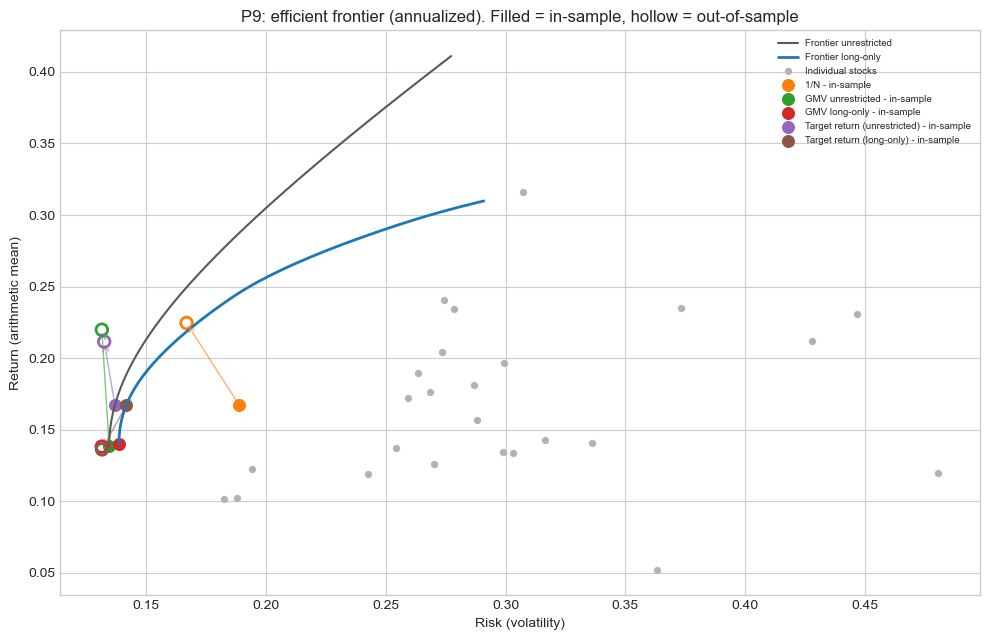

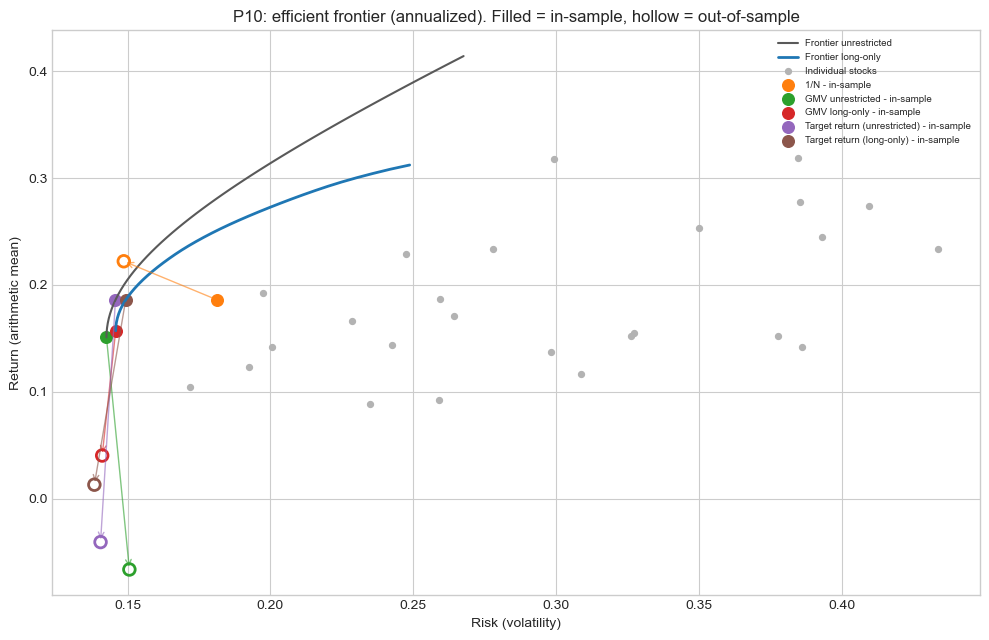

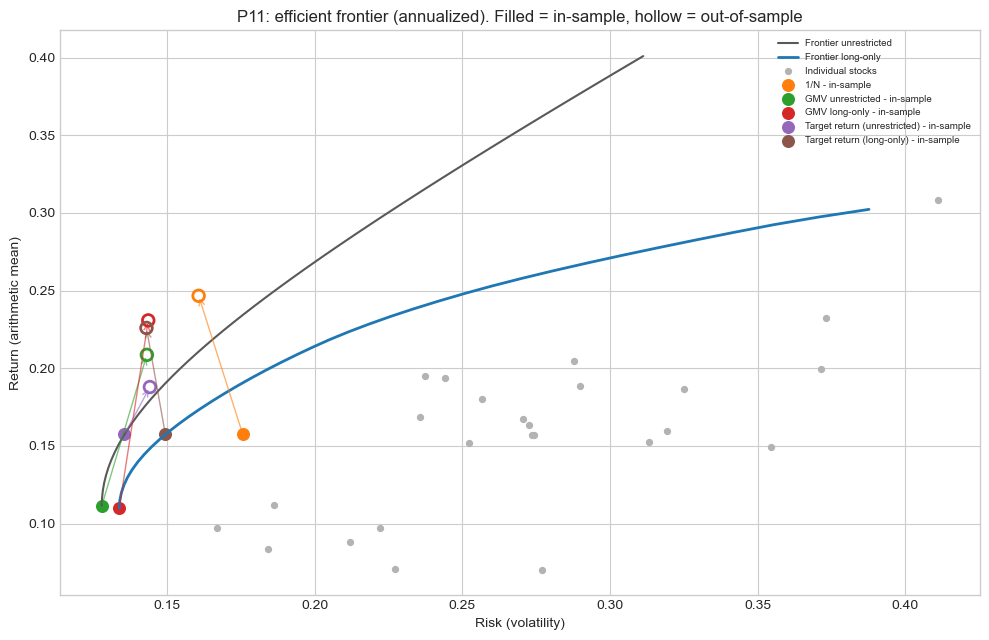

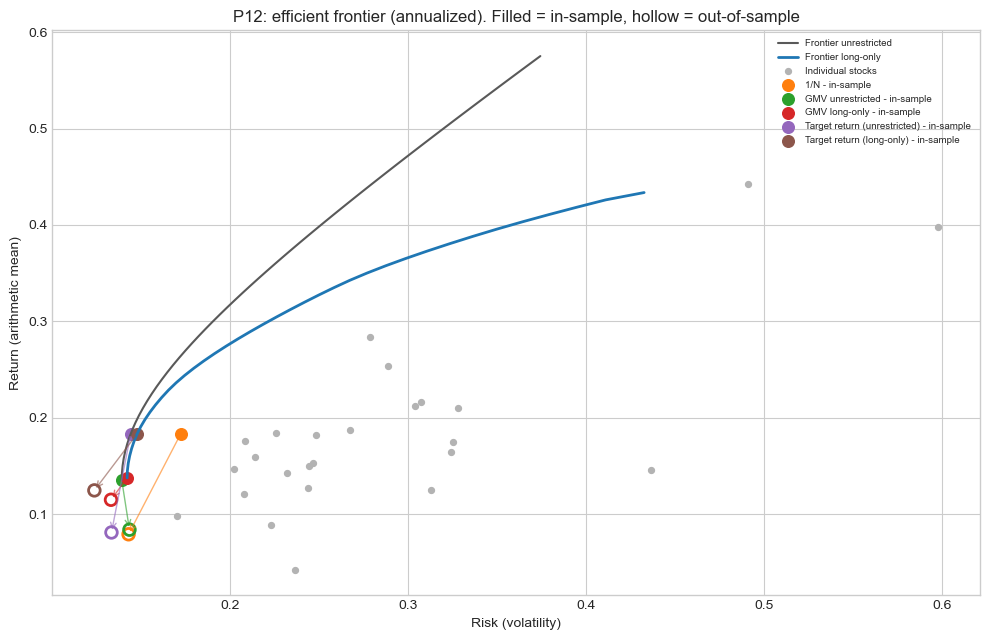

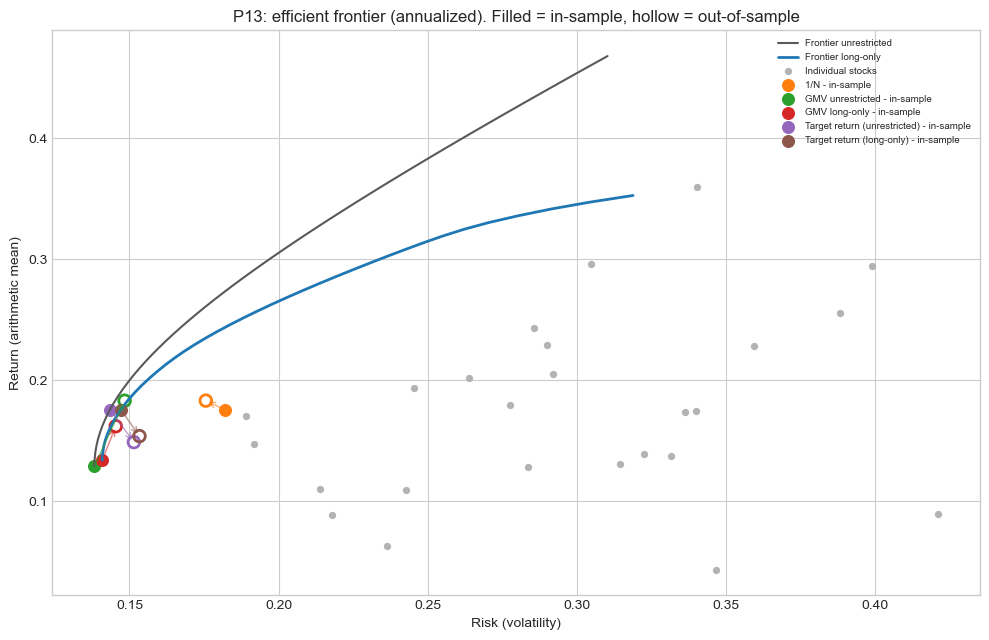

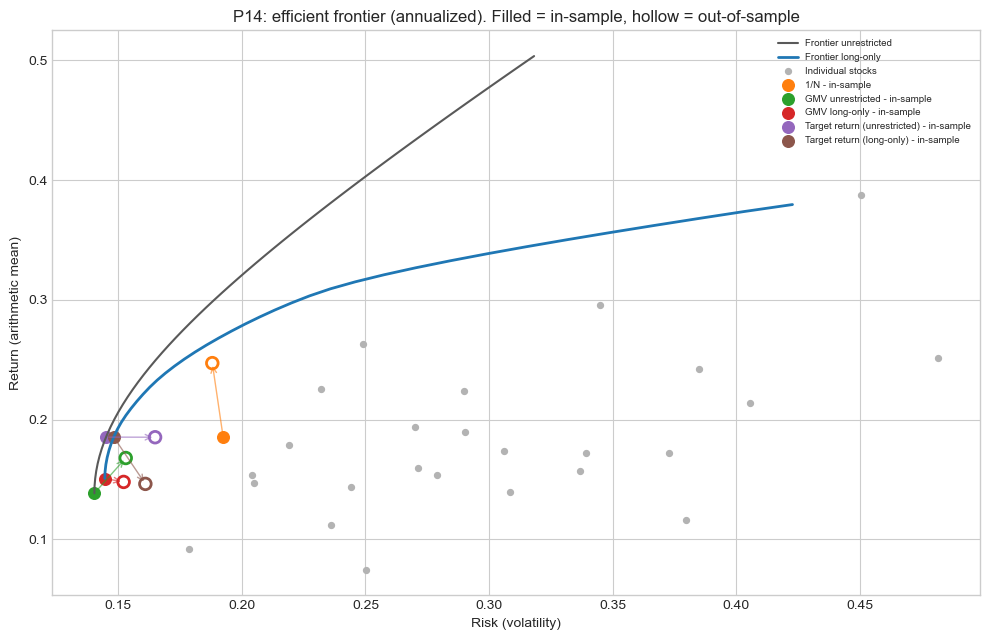

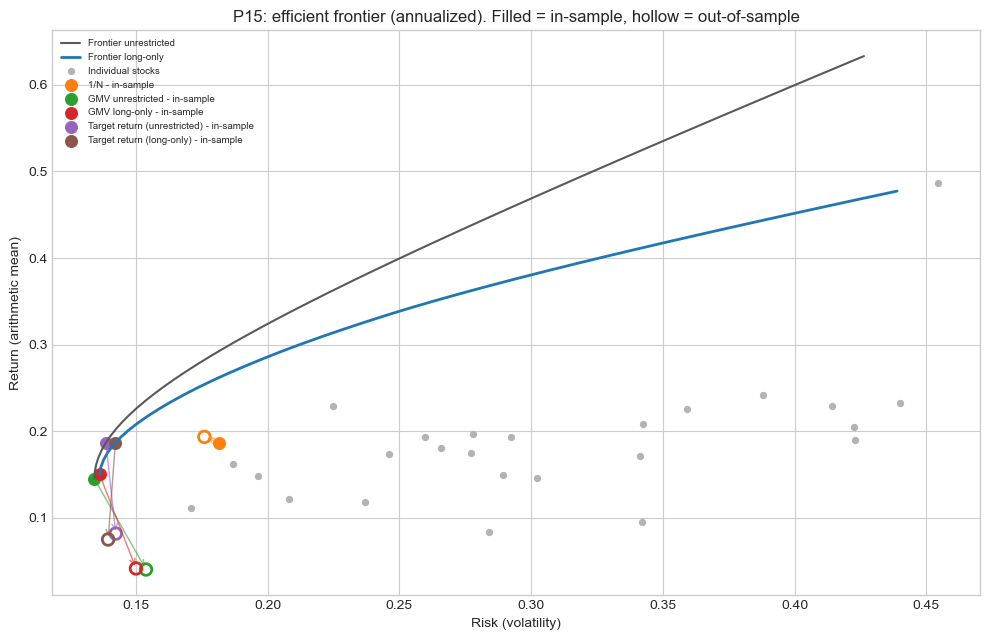

In [124]:
#EFFICIENT FRONTIER : COMPARE IN-SAMPLE AND OUTOFSAMPLE IN RISK-RETURN PLOT

for PID in [f"P{i}" for i in range(16)]:
    tk = portfolios[PID]
    mu = est[tk].mean().to_numpy() * TRADING_DAYS
    S = est[tk].cov().to_numpy() * TRADING_DAYS
    risk = lambda w: np.sqrt(w @ S @ w)

    r_gmv = w_gmv_unrestricted(mu, S) @ mu                 # return of min vol
    fr_u = [(risk(w), w @ mu) for w in (w_target_unrestricted(mu, S, R) for R in np.linspace(r_gmv, mu.max() * 1.3, 60))]
    r_lo = w_optimize(mu, S) @ mu
    fr_l = [(risk(w), w @ mu) for w in (w_optimize(mu, S, target=R) for R in np.linspace(r_lo, mu.max() * 0.98, 40))]

    fig, ax = plt.subplots(figsize=(10, 6.5))
    ax.plot(*zip(*fr_u), color="0.35", label="Frontier unrestricted")
    ax.plot(*zip(*fr_l), color="tab:blue", lw=2, label="Frontier long-only")
    ax.scatter(np.sqrt(np.diag(S)), mu, s=18, color="0.7", label="Individual stocks")
    res = results[results.portfolio == PID]
    for i, row in enumerate(res.itertuples()):
        c = f"C{i + 1}"
        ax.scatter(row.vol_in, row.ret_in, color=c, s=70, label=f"{row.model} - in-sample")
        ax.scatter(row.vol_oos, row.ret_oos, facecolors="none", edgecolors=c, s=70, linewidths=2)   # hollow = out-of-sample
        ax.annotate("", (row.vol_oos, row.ret_oos), (row.vol_in, row.ret_in), arrowprops=dict(arrowstyle="->", color=c, alpha=0.6))
    ax.set(title=f"{PID}: efficient frontier (annualized). Filled = in-sample, hollow = out-of-sample",
       xlabel="Risk (volatility)", ylabel="Return (arithmetic mean)")
    ax.legend(fontsize=7); plt.tight_layout(); plt.show()

In [126]:
display(pd.DataFrame({m: weights["P0",m] for m in ["GMV long-only", "GMV unrestricted"]}).mul(100).round(2))
display(pd.DataFrame({m: weights["P15",m] for m in ["GMV long-only", "GMV unrestricted"]}).mul(100).round(2))

,GMV long-only,GMV unrestricted
TMUS,0.12,1.28
DRI,0.00,0.81
ORLY,6.80,7.50
BBY,0.00,1.13
KDP,17.12,16.79
CHD,21.51,20.13
IBKR,4.51,5.93
BRK-B,9.64,14.37
AIZ,0.99,2.32
FISV,0.00,-2.60


,GMV long-only,GMV unrestricted
F,0.00,0.43
GRMN,4.12,5.68
EXPE,0.58,1.85
HRL,15.86,15.25
PG,28.45,27.74
VLO,0.00,0.92
GPN,0.00,-2.20
FDS,1.25,4.05
PGR,6.78,7.99
DVA,6.48,7.15


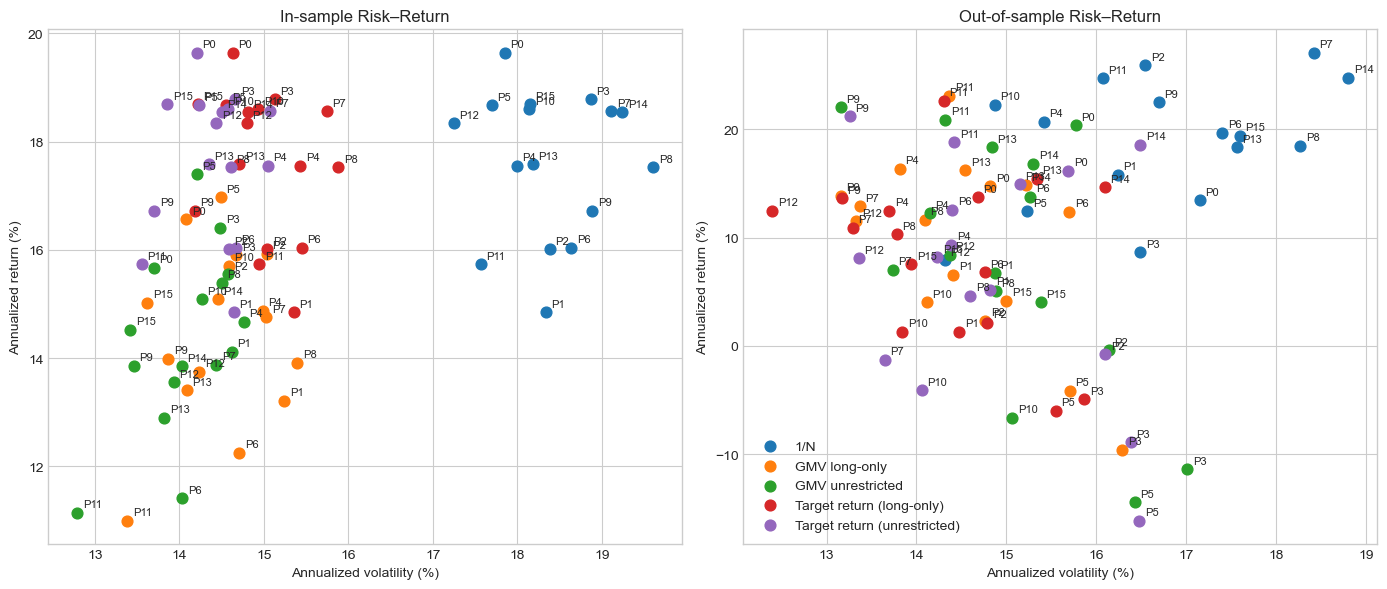

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, ret_col, risk_col, title in [
    (axes[0], "ret_in", "vol_in", "In-sample Risk–Return"),
    (axes[1], "ret_oos", "vol_oos", "Out-of-sample Risk–Return")]:
    for model, df in results.groupby("model"):
        ax.scatter(df[risk_col] * 100, df[ret_col] * 100, label=model, s=60)
        for _, row in df.iterrows():
            ax.annotate(row["portfolio"], (row[risk_col] * 100, row[ret_col] * 100),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)

    ax.set_xlabel("Annualized volatility (%)")
    ax.set_ylabel("Annualized return (%)")
    ax.set_title(title)
ax.legend()
plt.tight_layout()
plt.show()

holding1Y: 14s
holding1Q: 54s
holding1M: 152s
holding1W: 609s


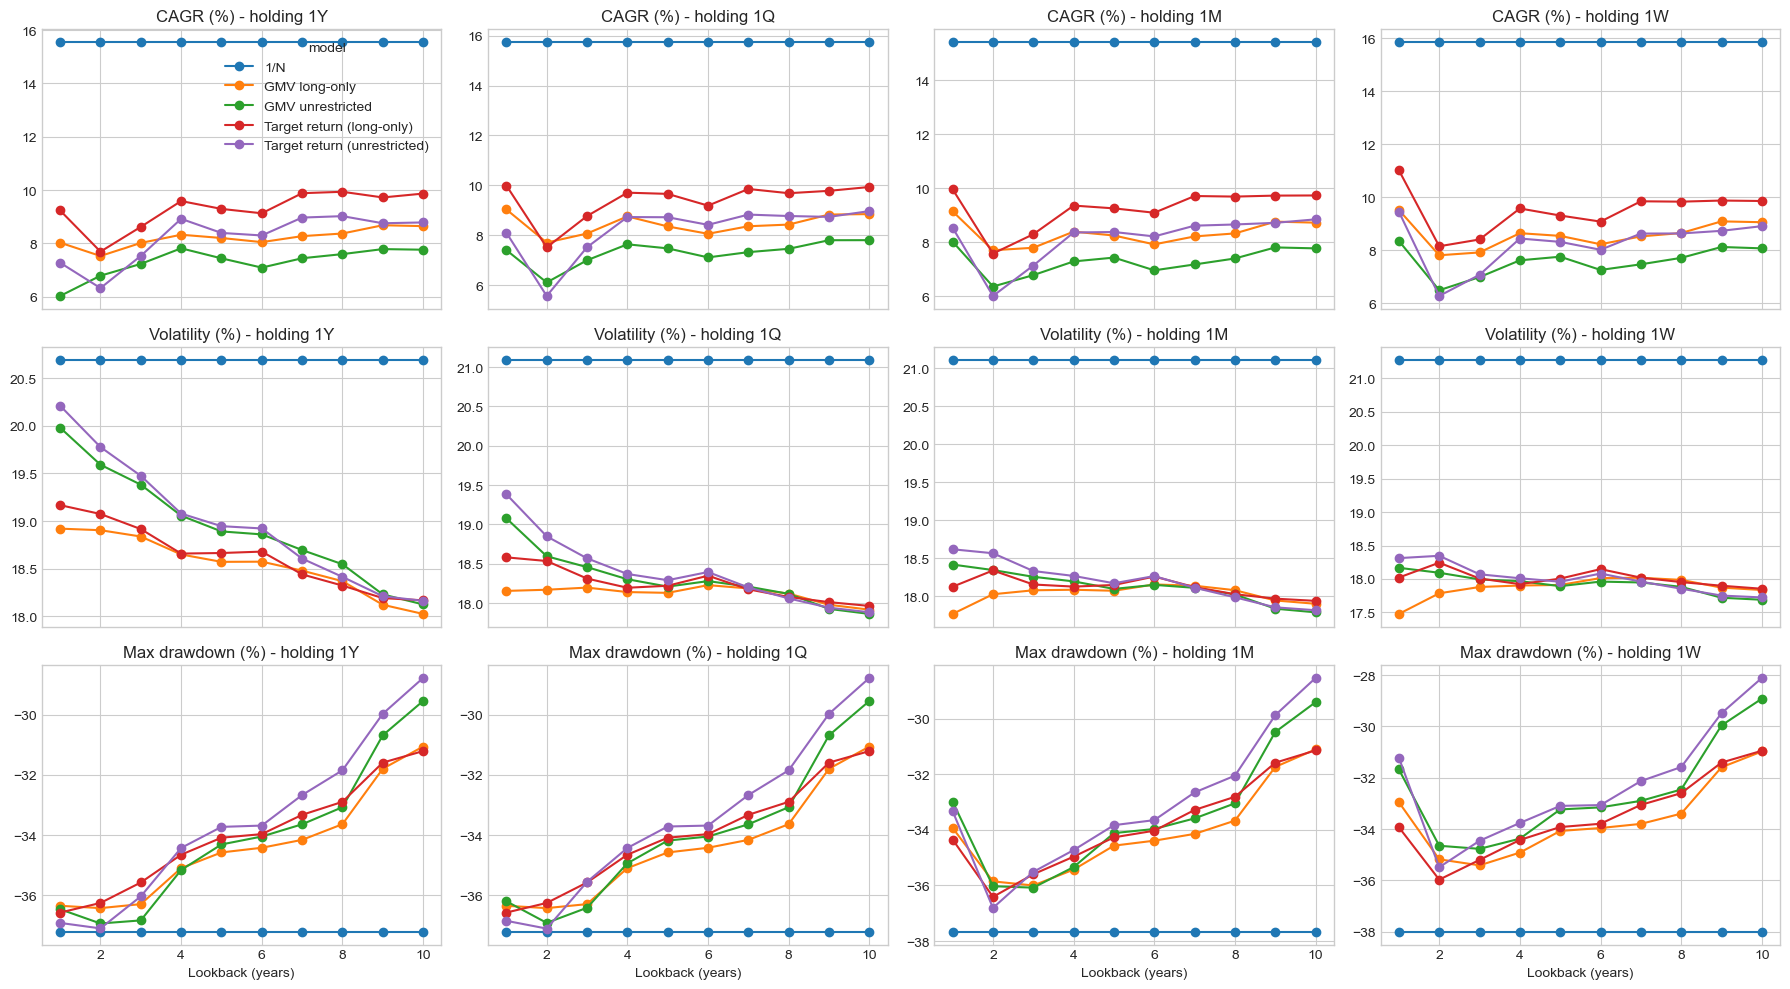

holding     1M                                                           \
model      1/N GMV long-only GMV unrestricted Target return (long-only)   
lookback                                                                  
1         0.73          0.52             0.44                      0.55   
2         0.73          0.43             0.35                      0.42   
3         0.73          0.43             0.37                      0.46   
4         0.73          0.47             0.40                      0.52   
5         0.73          0.46             0.41                      0.51   
6         0.73          0.44             0.39                      0.50   
7         0.73          0.46             0.40                      0.54   
8         0.73          0.46             0.42                      0.54   
9         0.73          0.49             0.45                      0.54   
10        0.73          0.49             0.44                      0.55   

holding                                  1Q                                 \
model    Target return (unrestricted)   1/N GMV long-only GMV unrestricted   
lookback                                                                     
1                                0.46  0.75          0.50             0.39   
2                                0.33  0.75          0.43             0.33   
3                                0.39  0.75          0.45             0.38   
4                                0.46  0.75          0.49             0.42   
5                                0.47  0.75          0.46             0.41   
6                                0.45  0.75          0.45             0.39   
7                                0.48  0.75          0.46             0.41   
8                                0.49  0.75          0.47             0.42   
9                                0.49  0.75          0.50             0.44   
10                               0.50  0.75          0.50             0.44   

holding                                                            1W  \
model    Target return (long-only) Target return (unrestricted)   1/N   
lookback                                                                
1                             0.54                         0.42  0.75   
2                             0.41                         0.30  0.75   
3                             0.48                         0.41  0.75   
4                             0.54                         0.48  0.75   
5                             0.53                         0.48  0.75   
6                             0.50                         0.46  0.75   
7                             0.54                         0.49  0.75   
8                             0.54                         0.49  0.75   
9                             0.55                         0.49  0.75   
10                            0.56                         0.51  0.75   

holding                                                            \
model    GMV long-only GMV unrestricted Target return (long-only)   
lookback                                                            
1                 0.55             0.47                      0.61   
2                 0.44             0.36                      0.45   
3                 0.44             0.39                      0.47   
4                 0.49             0.43                      0.54   
5                 0.48             0.44                      0.52   
6                 0.46             0.41                      0.50   
7                 0.48             0.42                      0.55   
8                 0.48             0.44                      0.55   
9                 0.51             0.47                      0.56   
10                0.51             0.46                      0.56   

holding                                  1Y                                 \
model    Target return (unrestricted)   1/N GMV long-only GMV unrestricted   
lookb

In [103]:
import time

END = "2026-06-30"
R = returns_all.loc[:END] #daily return till the end
LOOKBACKS_BT = list(range(1,11))
HOLDING = {"1Y": "Y", "1Q": "Q", "1M": "M", "1W": "W"} #holding period
START = f"{R.index[0].year + max(LOOKBACKS_BT)}-01-01"

_est_cache = {}
def get_estimated(d,L):
    #mu, cov annualized in [d-L years]
    if (d,L) not in _est_cache:
        train = R.loc[d-pd.DateOffset(years=L): d - pd.Timedelta(days=1)]
        _est_cache[(d,L)] = (train.mean()*TRADING_DAYS, train.cov()*TRADING_DAYS)
    return _est_cache[(d,L)] 

def rebalance_dates(freq_code):
    idx = pd.Series(R.index, index = R.index).loc[START:]
    return list(idx.groupby(idx.index.to_period(freq_code)).first())
    #first trading day of each period

def run_backtest(freq_code):
    dates = rebalance_dates(freq_code)
    ends = dates[1:] + [R.index[-1] + pd.Timedelta(days=1)]
    col = {t: i for i, t in enumerate(R.columns)}
    idxs = {pid: [col[t] for t in tk] for pid, tk in portfolios.items()}
    out = {}
    for d, d_end in zip(dates, ends):
        _est_cache.clear()      # chỉ giữ cache của ngày hiện tại
        hold = R.loc[d: d_end - pd.Timedelta(days=1)]
        growth = (1+hold).cumprod().to_numpy()
        for L in LOOKBACKS_BT:
            mu_f, S_f = get_estimated(d,L)
            mu_all, S_all = mu_f.to_numpy(), S_f.to_numpy()
            for pid, ix in idxs.items():
                mu, S, g = mu_all[ix], S_all[np.ix_(ix,ix)], growth[:,ix]
                for name, model in MODELS.items():
                    w = model(mu,S)
                    V = np.r_[1.0, g@w]
                    out.setdefault((pid,L,name), []).append(pd.Series(V[1:]/V[:-1]-1, index=hold.index))
    return {k: pd.concat(v) for k, v in out.items()}

def summarize(daily,holding):
        rows = []
        for (pid, L, name), r in daily.items():
            wealth = (1+r).cumprod()
            cagr = wealth.iloc[-1]**(TRADING_DAYS/len(r)) - 1
            vol = r.std(ddof=1)*np.sqrt(TRADING_DAYS)
            rows.append({"holding": holding, "portfolio": pid, "lookback": L, "model": name,
                     "cagr": cagr, "vol": vol, "ret_per_risk": cagr/vol,
                     "max_dd": (wealth/wealth.cummax() - 1).min()})
        return rows

bt_rows = []
for label, code in HOLDING.items():
    t0 = time.time()
    bt_rows += summarize(run_backtest(code), label)
    print(f"holding{label}: {time.time() - t0:.0f}s")
bt = pd.DataFrame(bt_rows)

avg = bt.groupby(["holding", "model", "lookback"])[["cagr", "vol", "max_dd", "ret_per_risk"]].mean()   #mean of portfolio
fig, axes = plt.subplots(3, len(HOLDING), figsize=(4.5 * len(HOLDING), 10), sharex=True, squeeze=False)
for j, h in enumerate(HOLDING):
    for i, (m, title) in enumerate([("cagr", "CAGR"), ("vol", "Volatility"), ("max_dd", "Max drawdown")]):
        (avg.loc[h][m].unstack("model") * 100).plot(ax=axes[i, j], marker="o", legend=(i == 0 and j == 0), title=f"{title} (%) - holding {h}")
        axes[i, j].set_xlabel("Lookback (years)")
plt.tight_layout(); plt.show()
display((bt.pivot_table(index="lookback", columns=["holding", "model"], values="ret_per_risk")).round(2))

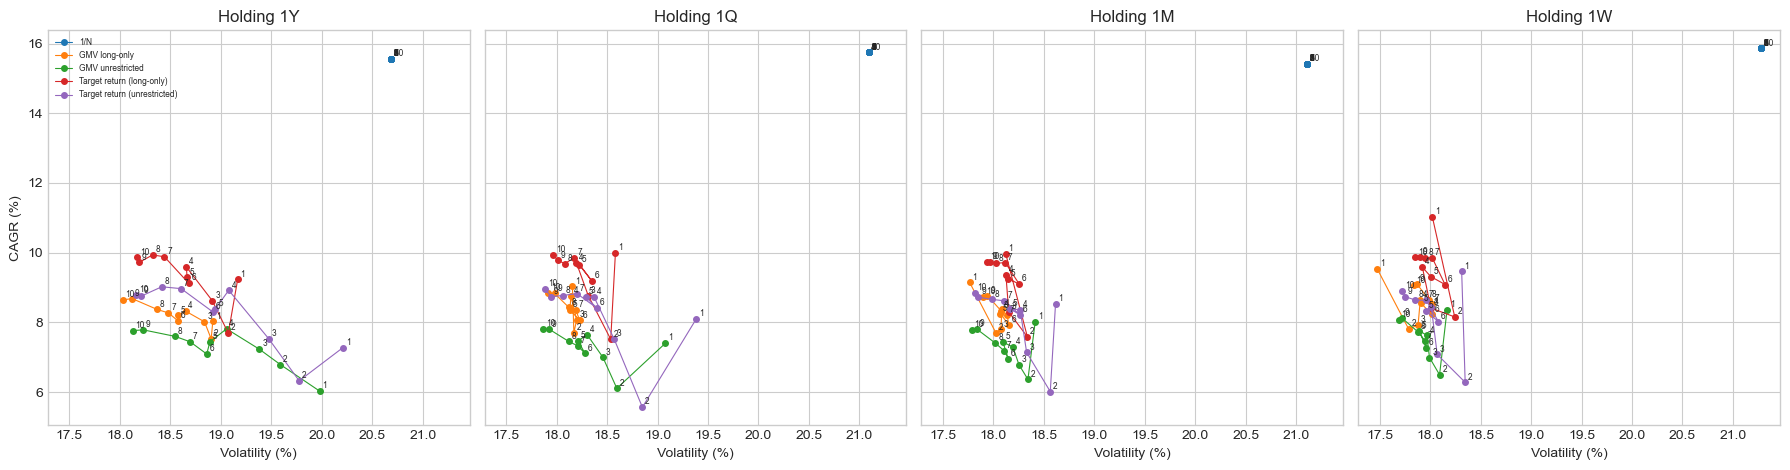

In [105]:
#risk-return of backtest (mỗi chấm = 1 mô hình x 1 lookback, số trên chấm = lookback)
fig, axes = plt.subplots(1, len(HOLDING), figsize=(4.5 * len(HOLDING), 4.8), sharex=True, sharey=True, squeeze=False)
for ax, h in zip(axes[0], HOLDING):
    for m, g in avg.loc[h].groupby("model"):
        g = g.droplevel("model")
        ax.plot(g["vol"] * 100, g["cagr"] * 100, marker="o", ms=4, lw=0.8, label=m)         # nối theo thứ tự lookback 1 -> 10
        for L, row in g.iterrows():
            ax.annotate(str(L), (row["vol"] * 100, row["cagr"] * 100), fontsize=6, xytext=(2, 2), textcoords="offset points")
    ax.set(title=f"Holding {h}", xlabel="Volatility (%)")
axes[0, 0].set_ylabel("CAGR (%)"); axes[0, 0].legend(fontsize=6)
plt.tight_layout(); plt.show()